In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/healthcare_data_for_task.csv")

In [3]:
df.head()

,Patient_ID,Age,Gender,Blood_Type,Medical_Condition,Medical_Code,Date_of_Admission,Discharge_Date,Admission_Type,Billing_Amount
0,P0001,47,Male,AB+,Heart Disease,HEA004,2025-05-10,2025-05-16,Emergency,23218.31
1,P0002,62,Female,AB-,Diabetes,DIA001,2025-12-31,2026-01-02,Emergency,47010.56
2,P0003,36,Male,AB-,Heart Disease,HEA004,2025-11-10,2025-11-27,Emergency,39619.01
3,P0004,51,Male,A+,Heart Disease,HEA004,2023-05-02,2023-05-07,Elective,35963.71
4,P0005,30,Male,A+,Diabetes,DIA001,2024-04-11,2024-04-17,Urgent,64615.93


In [4]:
df.shape

(1000, 10)

In [5]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Blood_Type', 'Medical_Condition',
       'Medical_Code', 'Date_of_Admission', 'Discharge_Date', 'Admission_Type',
       'Billing_Amount'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         1000 non-null   object 
 1   Age                1000 non-null   int64  
 2   Gender             1000 non-null   object 
 3   Blood_Type         1000 non-null   object 
 4   Medical_Condition  1000 non-null   object 
 5   Medical_Code       970 non-null    object 
 6   Date_of_Admission  1000 non-null   object 
 7   Discharge_Date     1000 non-null   object 
 8   Admission_Type     1000 non-null   object 
 9   Billing_Amount     1000 non-null   float64
dtypes: float64(1), int64(1), object(8)
memory usage: 78.3+ KB


In [7]:
df['Age']


,Age
0,47
1,62
2,36
3,51
4,30
...,...
995,24
996,63
997,63
998,33


In [8]:
df['Medical_Code']

,Medical_Code
0,HEA004
1,DIA001
2,HEA004
3,HEA004
4,DIA001
...,...
995,DIA001
996,DIA001
997,DIA001
998,DIA001


In [9]:
df.isnull().sum()

,0
Patient_ID,0
Age,0
Gender,0
Blood_Type,0
Medical_Condition,0
Medical_Code,30
Date_of_Admission,0
Discharge_Date,0
Admission_Type,0
Billing_Amount,0


In [10]:
df['Medical_Code'] = df['Medical_Code'].fillna('Unknown')

In [11]:
df['Admission_Type'] = (
    df['Admission_Type']
    .str.strip()
    .str.title()
)

In [12]:
df['Admission_Type'].unique()

array(['Emergency', 'Elective', 'Urgent'], dtype=object)

In [13]:
df['Admission_Type'].value_counts()

,count
Admission_Type,
Emergency,381
Elective,368
Urgent,251


In [14]:
df['Date_of_Admission'] = pd.to_datetime(df['Date_of_Admission'])

In [15]:
df['Discharge_Date'] = pd.to_datetime(df['Discharge_Date'])

In [16]:
df['Date_of_Admission'].dt.year

,Date_of_Admission
0,2025
1,2025
2,2025
3,2023
4,2024
...,...
995,2023
996,2025
997,2023
998,2023


In [17]:
df['Date_of_Admission'].dt.month

,Date_of_Admission
0,5
1,12
2,11
3,5
4,4
...,...
995,3
996,4
997,5
998,2


In [18]:
df['Date_of_Admission'].dt.day

,Date_of_Admission
0,10
1,31
2,10
3,2
4,11
...,...
995,16
996,17
997,8
998,11


In [19]:
df['Stay_Date'] = (
    df['Discharge_Date'] - df['Date_of_Admission']
).dt.days

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Patient_ID         1000 non-null   object        
 1   Age                1000 non-null   int64         
 2   Gender             1000 non-null   object        
 3   Blood_Type         1000 non-null   object        
 4   Medical_Condition  1000 non-null   object        
 5   Medical_Code       1000 non-null   object        
 6   Date_of_Admission  1000 non-null   datetime64[ns]
 7   Discharge_Date     1000 non-null   datetime64[ns]
 8   Admission_Type     1000 non-null   object        
 9   Billing_Amount     1000 non-null   float64       
 10  Stay_Date          1000 non-null   int64         
dtypes: datetime64[ns](2), float64(1), int64(2), object(6)
memory usage: 86.1+ KB


In [21]:
df['Billing_Amount'].describe()

,Billing_Amount
count,1000.000000
mean,77117.515720
std,41955.242269
min,5568.160000
25%,40318.785000
50%,77293.900000
75%,113089.267500
max,149921.800000


In [22]:
df.groupby('Medical_Condition')['Age'].mean()

,Age
Medical_Condition,
Arthritis,52.674641
Asthma,49.919598
Diabetes,53.130653
Heart Disease,52.180995
Hypertension,51.395349


In [23]:
pd.crosstab(
    df['Medical_Condition'],
    df['Gender']
)

Gender,Female,Male
Medical_Condition,,
Arthritis,95,114
Asthma,101,98
Diabetes,110,89
Heart Disease,104,117
Hypertension,80,92


<Axes: xlabel='Admission_Type'>

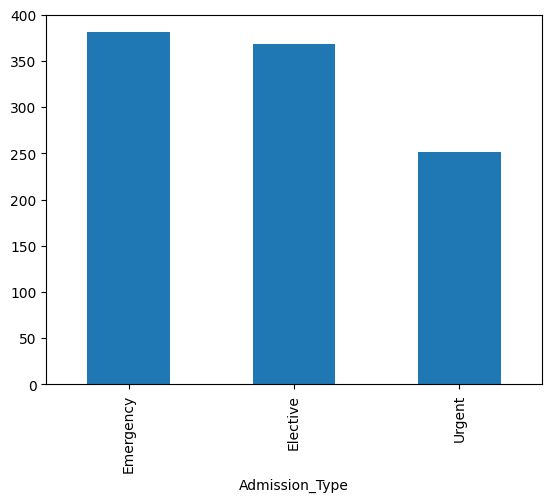

In [24]:
df['Admission_Type'].value_counts().plot(kind='bar')

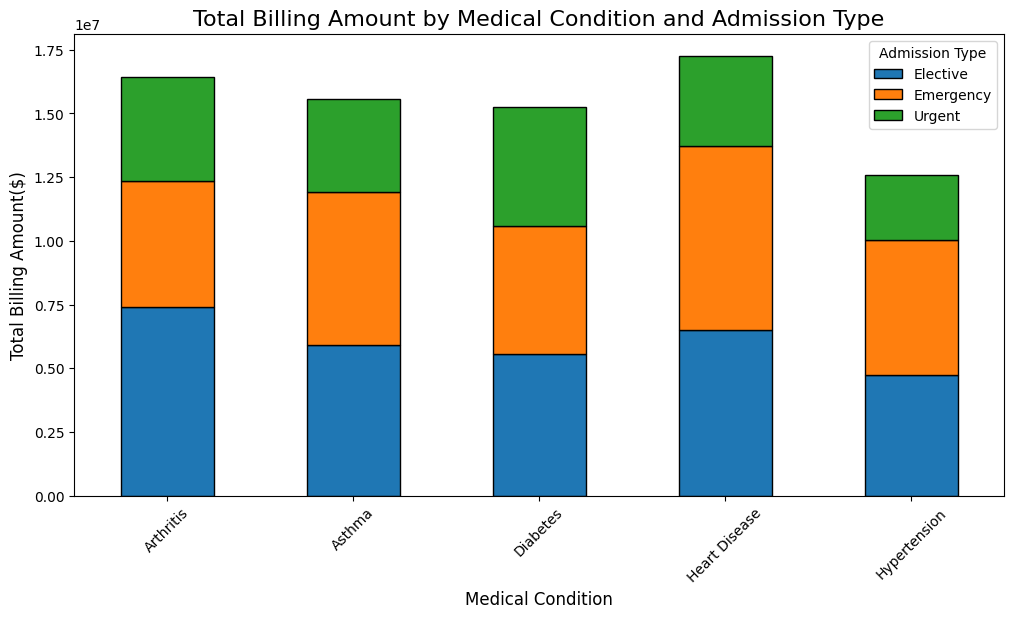

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

billing_summary = (
    df.groupby(['Medical_Condition','Admission_Type'])['Billing_Amount']
    .sum()
    .unstack()
)

billing_summary.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6),
    edgecolor='black'
)

plt.title('Total Billing Amount by Medical Condition and Admission Type',fontsize=16)
plt.xlabel('Medical Condition',fontsize=12)
plt.ylabel('Total Billing Amount($)',fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Admission Type')
plt.show()

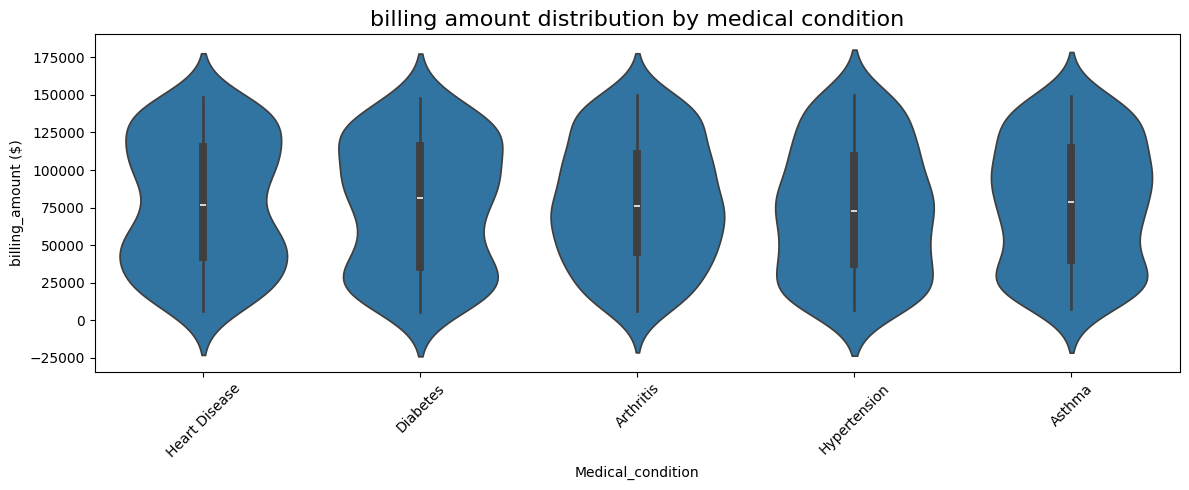

In [26]:
plt.figure(figsize=(12, 5))

sns.violinplot(
    data=df,
    x='Medical_Condition',
    y='Billing_Amount'
)

plt.title('billing amount distribution by medical condition', fontsize=16)

plt.xlabel('Medical_condition')
plt.ylabel('billing_amount ($)')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [27]:
df['Date_of_Admission']=pd.to_datetime(
    df['Date_of_Admission']
)

In [28]:
monthly_admissions=(
    df.set_index('Date_of_Admission')
    .resample('ME')
    .size()
)
print(monthly_admissions)

Date_of_Admission
2023-01-31    35
2023-02-28    29
2023-03-31    26
2023-04-30    33
2023-05-31    31
2023-06-30    25
2023-07-31    23
2023-08-31    27
2023-09-30    23
2023-10-31    19
2023-11-30    19
2023-12-31    23
2024-01-31    23
2024-02-29    24
2024-03-31    24
2024-04-30    25
2024-05-31    31
2024-06-30    23
2024-07-31    29
2024-08-31    19
2024-09-30    23
2024-10-31    33
2024-11-30    32
2024-12-31    30
2025-01-31    33
2025-02-28    28
2025-03-31    39
2025-04-30    34
2025-05-31    34
2025-06-30    26
2025-07-31    25
2025-08-31    33
2025-09-30    24
2025-10-31    36
2025-11-30    28
2025-12-31    31
Freq: ME, dtype: int64


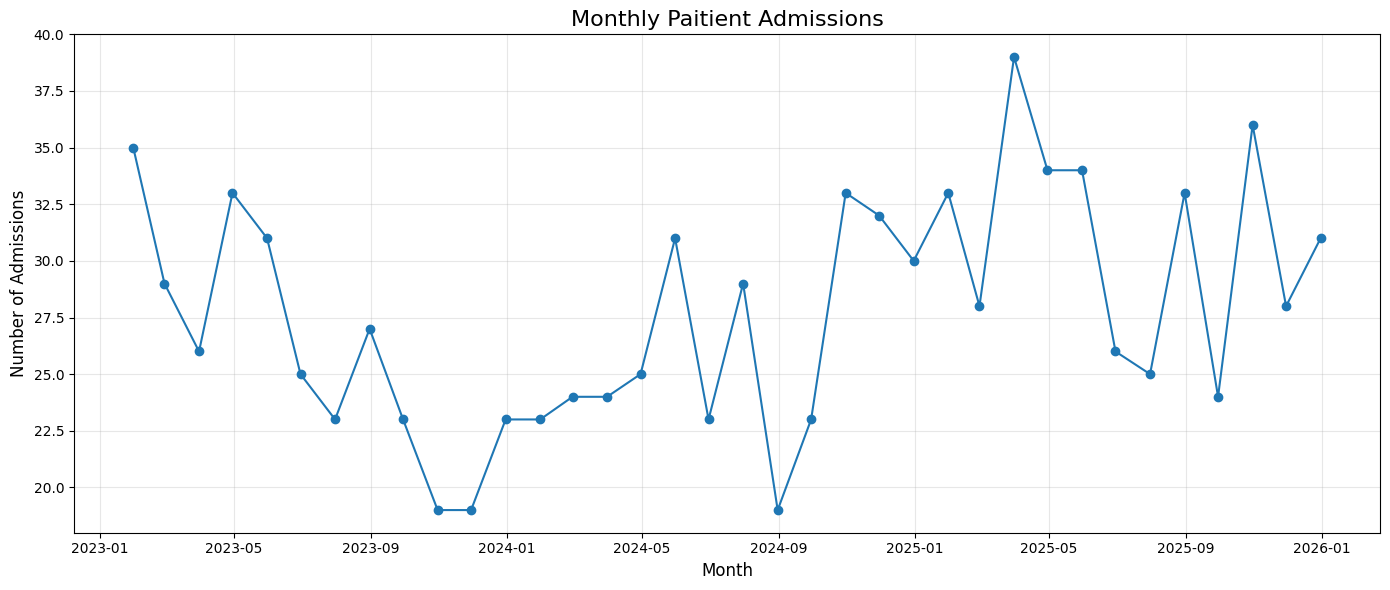

In [29]:
plt.figure(figsize=(14,6))
plt.plot(
    monthly_admissions.index,
    monthly_admissions.values,
    marker='o',
)
plt.title('Monthly Paitient Admissions',fontsize=16)
plt.xlabel('Month',fontsize=12)
plt.ylabel('Number of Admissions',fontsize=12)
plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

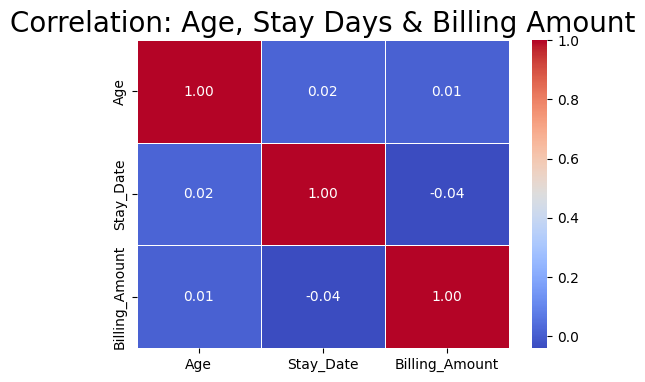

In [41]:
columns_to_check = ['Age', 'Stay_Date', 'Billing_Amount']
correlation_subset = df[columns_to_check].corr()
plt.figure(figsize=(6, 4))
sns.heatmap(correlation_subset, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation: Age, Stay Days & Billing Amount', fontsize=20)
plt.show()